# 실습 3-1 : Random Forest

#### **<실습 내용>**

1. 실습 데이터 탐색 및 전처리
- 분류 데이터 (MachineFailure)
- 회귀 데이터 (Concrete)

2. Random Forest Classifier
- 모델 학습 및 성능 평가
- 변수 중요도 시각화

3. Random Forest Regressor
- 모델 학습 및 성능 평가
- 변수 중요도 시각화

4. 하이퍼 파라미터 최적화
- GridSearchCV를 활용한 최적 파라미터 탐색

## 분석 준비

### 주요 라이브러리 호출

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

---

## 1) 분류 문제

In [2]:
MF_Data = pd.read_csv(os.path.join(os.getcwd(), "dataset", "day3-1_cls_data.csv"))
MF_Data.head()

,Temperature,Humidity,Operator,Measure1,Measure2,Measure3,Measure4,Measure5,Measure6,Measure7,Measure8,Measure9,Measure10,Measure11,Measure12,Measure13,Measure14,Measure15,Hours Since Previous Failure,Failure
0,67,82,Operator1,291,1,1,1041,846,334,706,1086,256,1295,766,968,1185,1355,1842,90,No
1,68,77,Operator1,1180,1,1,1915,1194,637,1093,524,919,245,403,723,1446,719,748,91,No
2,64,76,Operator1,1406,1,1,511,1577,1121,1948,1882,1301,273,1927,1123,717,1518,1689,92,No
3,63,80,Operator1,550,1,1,1754,1834,1413,1151,945,1312,1494,1755,1434,502,1336,711,93,No
4,65,81,Operator1,1928,1,2,1326,1082,233,1441,1736,1033,1549,802,1819,1616,1507,507,94,No


In [3]:
print("데이터 크기 :", MF_Data.shape)
print("출력변수 분포:")
print(MF_Data["Failure"].value_counts())

데이터 크기 : (7900, 20)
출력변수 분포:
Failure
No     7825
Yes      75
Name: count, dtype: int64


In [4]:
# 입출력 변수 분할
Y_cls = MF_Data["Failure"]
X_cls = MF_Data.drop(["Failure"], axis=1)

# 범주형 변수 처리
X_cls["Measure2"] = X_cls["Measure2"].astype("category")
X_cls["Measure3"] = X_cls["Measure3"].astype("category")
X_cls = pd.get_dummies(X_cls)
cls_columns = X_cls.columns

# 출력변수 인코딩
Y_cls = Y_cls.replace({"No": 0, "Yes": 1})

# 데이터 분할
X_train_cls, X_test_cls, Y_train_cls, Y_test_cls = train_test_split(
    X_cls, Y_cls, test_size=0.3, random_state=0, stratify=Y_cls)

print("학습 데이터 :", X_train_cls.shape)
print("테스트 데이터 :", X_test_cls.shape)

학습 데이터 : (5530, 31)
테스트 데이터 : (2370, 31)


C:\Users\Admin\AppData\Local\Temp\ipykernel_2844\2999565116.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  Y_cls = Y_cls.replace({"No": 0, "Yes": 1})


In [5]:
# 분류 성능 평가 함수
def get_classscore(real, pred):
    print("Accuracy  : %.3f" % accuracy_score(real, pred))
    print("Precision : %.3f" % precision_score(real, pred))
    print("Recall    : %.3f" % recall_score(real, pred))
    print("F1-score  : %.3f" % f1_score(real, pred))
    print()
    print("혼동행렬")
    print(confusion_matrix(real, pred))

---

### 1-1) Random Forest Classifier 모델 학습 및 성능 평가

> **Random Forest**는 Bagging의 일종으로, 붓스트랩 샘플링 + 무작위 변수 선택을 통해 다수의 의사결정나무를 생성하고 결합하는 앙상블 모델임
> - **붓스트랩 샘플링**: 학습 데이터에서 복원 추출로 여러 표본을 만들어 베이스 모델의 다양성을 확보함
> - **무작위 변수 선택**: 각 노드마다 입력변수의 일부만 랜덤 선택하여 트리 간 상관성을 줄임
> - 분류: 다수결 투표, 회귀: 평균으로 최종 예측을 수행함

In [7]:
RF_cls = RandomForestClassifier()
RF_cls.fit(X_train_cls, Y_train_cls)
RF_cls_pred = RF_cls.predict(X_test_cls)
get_classscore(Y_test_cls, RF_cls_pred)

Accuracy  : 0.997
Precision : 0.938
Recall    : 0.682
F1-score  : 0.789

혼동행렬
[[2347    1]
 [   7   15]]


### 1-2) 변수 중요도 시각화

> Random Forest는 **Mean Decrease in Impurity** 방식으로 변수 중요도를 산출함

> 각 트리에서 특정 변수가 노드 분할에 사용될 때의 불순도 감소량을 평균내어 중요도를 계산함

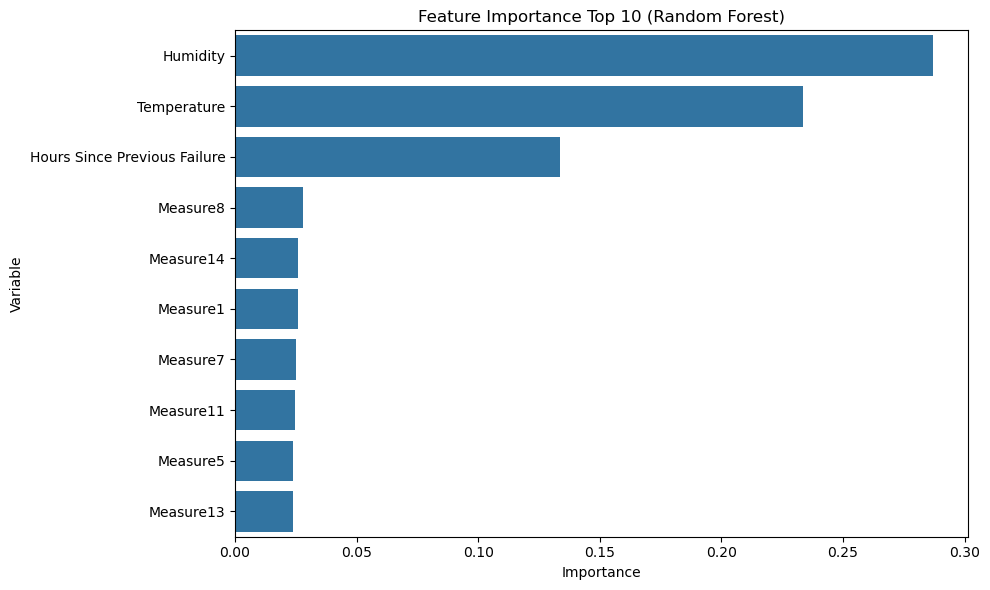

In [9]:
# 변수 중요도 추출 및 시각화
var_imp = pd.DataFrame({"Variable": cls_columns, "Importance": RF_cls.feature_importances_}) #변수와 중요도를 DF화
imp_top10 = var_imp.sort_values(by="Importance", ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Variable", data=imp_top10)
plt.title("Feature Importance Top 10 (Random Forest)") 
plt.tight_layout()
plt.show()

### 1-3) 모델 성능 개선

> Random Forest의 주요 하이퍼 파라미터:
>
> | 파라미터 | 의미 |
> |:---:|:---:|
> | n_estimators | 베이스 모델(의사결정나무)의 수 |
> | max_depth | 개별 트리의 최대 깊이 |
> | max_features | 각 노드에서 랜덤 선택하는 변수 수 (분류: sqrt, 회귀: n/3) |
> | min_samples_leaf | 끝 노드의 최소 샘플 수 |
> | min_samples_split | 노드 분할을 위한 최소 샘플 수 |

In [10]:
params = {
    "max_depth": [3, 5, 7],
    "min_samples_leaf": [2, 4, 8],
    "n_estimators": [100, 300],
    "max_features": ["sqrt", 3]
}

grid_cls = GridSearchCV(
    RandomForestClassifier(random_state=0),
    param_grid=params, cv=5, scoring="f1", n_jobs=-1
)
grid_cls.fit(X_train_cls, Y_train_cls)

print("최적 파라미터:", grid_cls.best_params_)
print("최적 F1-score: %.4f" % grid_cls.best_score_)

최적 파라미터: {'max_depth': 7, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 300}
최적 F1-score: 0.8058


In [11]:
# 최적 모델로 테스트 성능 평가
best_pred_cls = grid_cls.predict(X_test_cls)
get_classscore(Y_test_cls, best_pred_cls)

Accuracy  : 0.997
Precision : 1.000
Recall    : 0.727
F1-score  : 0.842

혼동행렬
[[2348    0]
 [   6   16]]


---

## 2) 회귀 문제

In [12]:
Concrete = pd.read_csv(os.path.join(os.getcwd(), "dataset", "day3-1_reg_data.csv"))

Y_reg = Concrete["Concrete_compressive_strength"]
X_reg = Concrete.drop(["Concrete_compressive_strength"], axis=1)

X_train_reg, X_test_reg, Y_train_reg, Y_test_reg = train_test_split(
    X_reg, Y_reg, test_size=0.3, random_state=0)

print("학습 데이터 :", X_train_reg.shape)
print("테스트 데이터 :", X_test_reg.shape)

학습 데이터 : (721, 8)
테스트 데이터 : (309, 8)


In [13]:
# 회귀 성능 평가 함수
def get_regscore(true, pred):
    print("MSE       : %.3f" % mean_squared_error(true, pred))
    print("RMSE      : %.3f" % np.sqrt(mean_squared_error(true, pred)))
    print("MAE       : %.3f" % mean_absolute_error(true, pred))
    print("R-squared : %.3f" % r2_score(true, pred))

### 2-1) Random Forest Regressor 모델 학습 및 성능 평가

In [14]:
RF_reg = RandomForestRegressor()
RF_reg.fit(X_train_reg, Y_train_reg)
RF_reg_pred = RF_reg.predict(X_test_reg)
get_regscore(Y_test_reg, RF_reg_pred)

MSE       : 27.159
RMSE      : 5.211
MAE       : 3.621
R-squared : 0.894


### 2-2) 변수 중요도 시각화

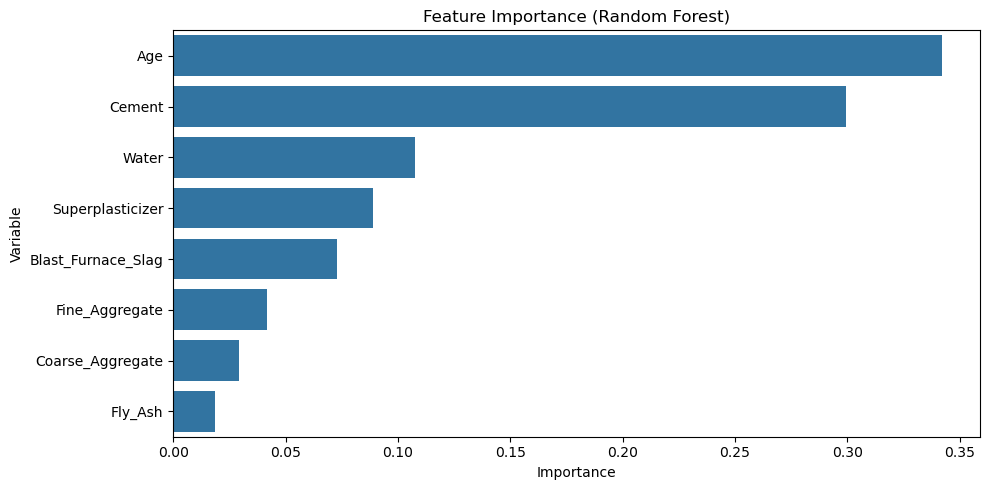

In [15]:
var_imp_reg = pd.DataFrame({"Variable": X_train_reg.columns, "Importance": RF_reg.feature_importances_})
var_imp_reg = var_imp_reg.sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x="Importance", y="Variable", data=var_imp_reg)
plt.title("Feature Importance (Random Forest)")
plt.tight_layout()
plt.show()

### 2-3) 예측 시각화

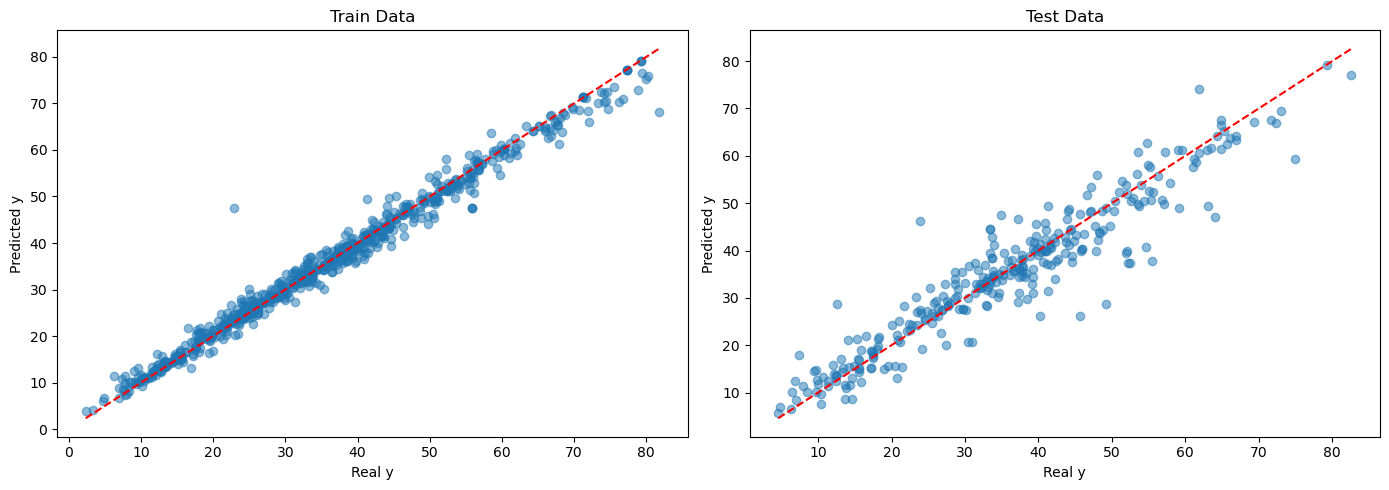

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5)) #subplot으로 1행2열 그리기

axes[0].scatter(Y_train_reg, RF_reg.predict(X_train_reg), alpha=0.5)
axes[0].plot([Y_train_reg.min(), Y_train_reg.max()], [Y_train_reg.min(), Y_train_reg.max()], "r--")
axes[0].set_xlabel("Real y"); axes[0].set_ylabel("Predicted y"); axes[0].set_title("Train Data")

axes[1].scatter(Y_test_reg, RF_reg_pred, alpha=0.5)
axes[1].plot([Y_test_reg.min(), Y_test_reg.max()], [Y_test_reg.min(), Y_test_reg.max()], "r--")
axes[1].set_xlabel("Real y"); axes[1].set_ylabel("Predicted y"); axes[1].set_title("Test Data")

plt.tight_layout()
plt.show()

### 2-4) 모델 성능 개선

In [18]:
params_reg = {
    "max_depth": [5, 10, 15],
    "min_samples_leaf": [2, 4],
    "n_estimators": [100, 300]
}

grid_reg = GridSearchCV(
    RandomForestRegressor(random_state=0),
    param_grid=params_reg, cv=5, scoring="r2", n_jobs=-1
)
grid_reg.fit(X_train_reg, Y_train_reg)

print("최적 파라미터:", grid_reg.best_params_)
print("최적 R-squared: %.4f" % grid_reg.best_score_)

최적 파라미터: {'max_depth': 15, 'min_samples_leaf': 2, 'n_estimators': 300}
최적 R-squared: 0.8902


In [19]:
# 최적 모델로 테스트 성능 평가
best_pred_reg = grid_reg.predict(X_test_reg)
get_regscore(Y_test_reg, best_pred_reg)

MSE       : 28.243
RMSE      : 5.314
MAE       : 3.787
R-squared : 0.890


---

## 5) Vibe Coding 실습

**[과제 1]**
지수는 Random Forest가 계산한 변수 중요도(Feature Importance)가 정말 중요한 변수를 의미하는지 궁금해졌습니다. AI와 상의하여 변수 중요도를 확인하고, 중요도가 높은 상위 변수만 사용했을 때와 전체 변수를 사용했을 때의 성능을 비교해 보세요. 결과를 바탕으로 "중요한 변수만 사용하면 항상 좋은 모델이 될까?"에 대해 자신의 의견을 정리해 보세요.

=== 변수 중요도 ===
             Variable  Importance
7                 Age    0.346577
0              Cement    0.294544
3               Water    0.107879
4    Superplasticizer    0.088226
1  Blast_Furnace_Slag    0.071467
6      Fine_Aggregate    0.043835
5    Coarse_Aggregate    0.028944
2             Fly_Ash    0.018527
누적 중요도: [0.34657737 0.6411215  0.74900095 0.83722714 0.90869436 0.952529
 0.98147254 1.        ]

선택된 주요 변수 (3개): ['Age', 'Cement', 'Water']
선택 변수 중요도 합: 0.749

=== 성능 비교 ===
[전체 변수 - Train] R²=0.983, RMSE=2.186, MAE=1.373
[전체 변수 - Test ] R²=0.896, RMSE=5.165, MAE=3.583
[주요 변수 - Train] R²=0.965, RMSE=3.156, MAE=2.168
[주요 변수 - Test ] R²=0.840, RMSE=6.404, MAE=4.666


C:\Users\Admin\AppData\Local\Temp\ipykernel_2844\939511530.py:76: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_2844\939511530.py:76: UserWarning: Glyph 52404 (\N{HANGUL SYLLABLE CE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_2844\939511530.py:76: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_2844\939511530.py:76: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_2844\939511530.py:76: UserWarning: Glyph 51452 (\N{HANGUL SYLLABLE JU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_2844\939511530.py:76: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) Dej

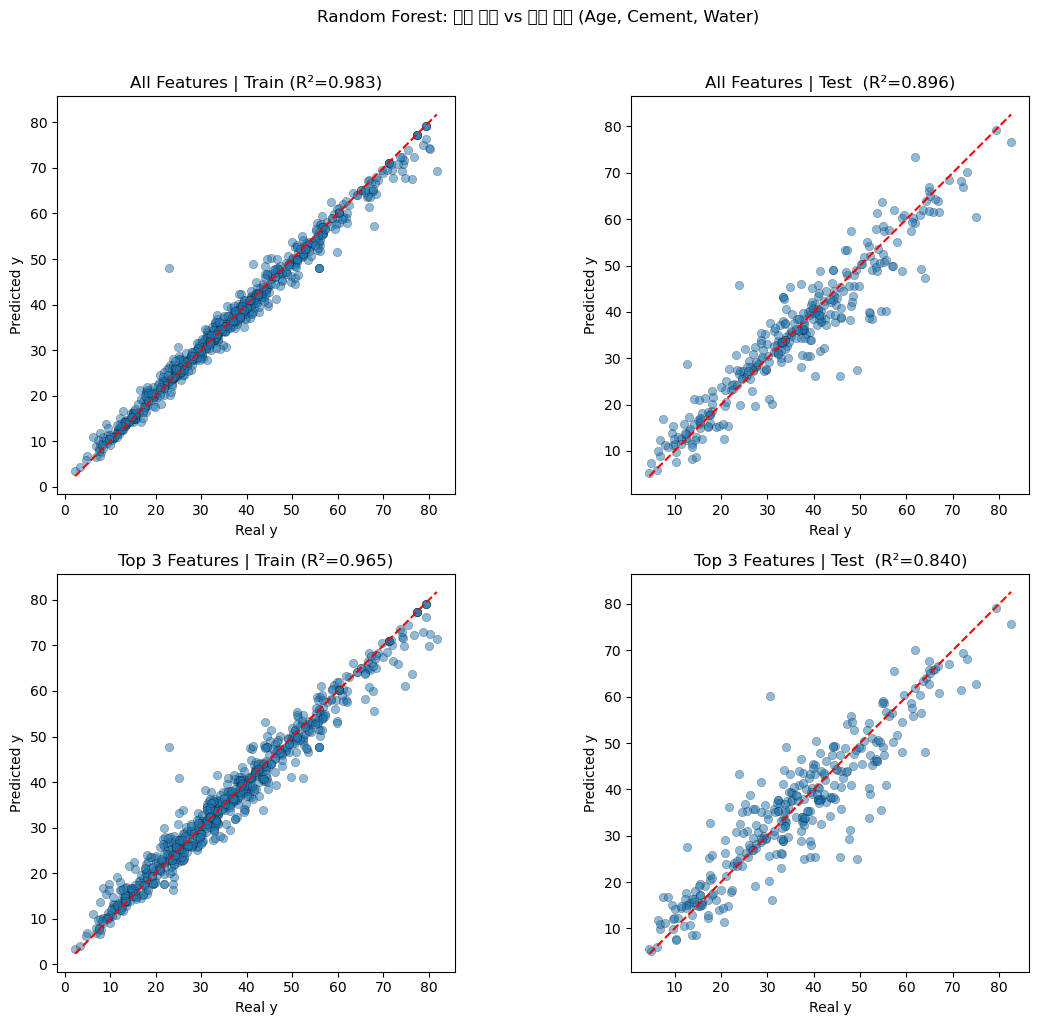

In [24]:
# ============================================================
# 주요 변수만 사용했을 때 Random Forest 성능 비교
# ============================================================

# 1) 전체 변수 모델 (기존과 동일)
RF_all = RandomForestRegressor(random_state=0)
RF_all.fit(X_train_reg, Y_train_reg)

pred_all_train = RF_all.predict(X_train_reg)
pred_all_test  = RF_all.predict(X_test_reg)

# 2) 변수 중요도 추출
var_imp_reg = pd.DataFrame({
    "Variable": X_train_reg.columns,
    "Importance": RF_all.feature_importances_
}).sort_values("Importance", ascending=False)

print("=== 변수 중요도 ===")
print(var_imp_reg)
print(f"누적 중요도: {var_imp_reg['Importance'].cumsum().values}")

# 3) 주요 변수 선택 (방법 A: 상위 k개 / 방법 B: 누적 80%)
TOP_K = 3                          # 상위 3개 변수 (원하면 조정)
# 또는 누적 80% 기준:
# cumsum = var_imp_reg["Importance"].cumsum()
# top_features = var_imp_reg.loc[cumsum <= 0.8, "Variable"].tolist()

top_features = var_imp_reg.head(TOP_K)["Variable"].tolist()
print(f"\n선택된 주요 변수 ({TOP_K}개): {top_features}")
print(f"선택 변수 중요도 합: {var_imp_reg.head(TOP_K)['Importance'].sum():.3f}")

# 4) 주요 변수만으로 모델 학습
X_train_top = X_train_reg[top_features]
X_test_top  = X_test_reg[top_features]

RF_top = RandomForestRegressor(random_state=0)
RF_top.fit(X_train_top, Y_train_reg)

pred_top_train = RF_top.predict(X_train_top)
pred_top_test  = RF_top.predict(X_test_top)

# 5) 성능 비교
def print_compare(name, y_true, y_pred):
    print(f"[{name}] R²={r2_score(y_true, y_pred):.3f}, "
          f"RMSE={np.sqrt(mean_squared_error(y_true, y_pred)):.3f}, "
          f"MAE={mean_absolute_error(y_true, y_pred):.3f}")

print("\n=== 성능 비교 ===")
print_compare("전체 변수 - Train", Y_train_reg, pred_all_train)
print_compare("전체 변수 - Test ", Y_test_reg,  pred_all_test)
print_compare("주요 변수 - Train", Y_train_reg, pred_top_train)
print_compare("주요 변수 - Test ", Y_test_reg,  pred_top_test)

# 6) 2×2 Scatter Plot
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

plots = [
  # (행, 열, 실제값, 예측값, 제목)
    (0, 0, Y_train_reg, pred_all_train, f"All Features | Train (R²={r2_score(Y_train_reg, pred_all_train):.3f})"),
    (0, 1, Y_test_reg,  pred_all_test,  f"All Features | Test  (R²={r2_score(Y_test_reg, pred_all_test):.3f})"),
    (1, 0, Y_train_reg, pred_top_train, f"Top {TOP_K} Features | Train (R²={r2_score(Y_train_reg, pred_top_train):.3f})"),
    (1, 1, Y_test_reg,  pred_top_test,  f"Top {TOP_K} Features | Test  (R²={r2_score(Y_test_reg, pred_top_test):.3f})"),
]

for row, col, y_true, y_pred, title in plots:
    ax = axes[row, col]
    ax.scatter(y_true, y_pred, alpha=0.5, edgecolors="k", linewidths=0.3)
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax.plot(lims, lims, "r--", lw=1.5)
    ax.set_xlabel("Real y")
    ax.set_ylabel("Predicted y")
    ax.set_title(title)
    ax.set_aspect("equal", adjustable="box")

plt.suptitle(f"Random Forest: 전체 변수 vs 주요 변수 ({', '.join(top_features)})", y=1.02)
plt.tight_layout()
plt.show()

보통 변수를 줄이면:

Train R²가 더 많이 떨어지고 (과적합 감소)
Test는 덜 떨어지거나 비슷한 경우가 많음
지금은 반대입니다.

→ 빼둔 변수들이 Test에서도 실제로 도움이 되는 정보였다는 뜻에 가깝습니다.
→ 단순화로 과적합을 줄인 게 아니라, 일반화에 필요한 신호를 잘라낸 것에 가깝습니다.

**[과제 2]** 지수는 Random Forest가 단일 의사결정나무보다 항상 더 좋은 성능을 보이는지 궁금해졌습니다. 동일한 데이터로 단일 의사결정나무 모델을 학습시켜 이번 실습의 Random Forest 모델과 성능을 비교해 보세요. 그리고 그 차이가 나타나는 이유를 AI와 상의하여 해석해 보세요.

In [25]:
# ============================================================
# Random Forest vs 단일 의사결정나무 성능 비교
# ============================================================

from sklearn.tree import DecisionTreeRegressor


# 1) 모델 학습 (동일한 train 데이터, random_state=0)
DT_reg = DecisionTreeRegressor(random_state=0)
DT_reg.fit(X_train_reg, Y_train_reg)

RF_reg = RandomForestRegressor(random_state=0)
RF_reg.fit(X_train_reg, Y_train_reg)

# 2) 예측
models = {
    "Decision Tree": {
        "train_pred": DT_reg.predict(X_train_reg),
        "test_pred":  DT_reg.predict(X_test_reg),
    },
    "Random Forest": {
        "train_pred": RF_reg.predict(X_train_reg),
        "test_pred":  RF_reg.predict(X_test_reg),
    },
}

# 3) 성능 지표를 표로 정리
results = []
for name, preds in models.items():
    for split, y_true, y_pred in [
        ("Train", Y_train_reg, preds["train_pred"]),
        ("Test",  Y_test_reg,  preds["test_pred"]),
    ]:
        results.append({
            "Model": name,
            "Split": split,
            "R2":    r2_score(y_true, y_pred),
            "RMSE":  np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE":   mean_absolute_error(y_true, y_pred),
        })

result_df = pd.DataFrame(results)
print("=== 성능 비교표 ===")
print(result_df.round(3).to_string(index=False))

# 4) Train - Test R² 차이 (과적합 정도)
print("\n=== Train - Test R² 차이 (클수록 과적합) ===")
for name in models:
    r2_train = result_df[(result_df["Model"] == name) & (result_df["Split"] == "Train")]["R2"].values[0]
    r2_test  = result_df[(result_df["Model"] == name) & (result_df["Split"] == "Test")]["R2"].values[0]
    print(f"{name:15s}: {r2_train - r2_test:.3f}")

# 5) get_regscore로 상세 출력
for name, preds in models.items():
    print(f"\n=== {name} | Test ===")
    get_regscore(Y_test_reg, preds["test_pred"])

=== 성능 비교표 ===
        Model Split    R2  RMSE   MAE
Decision Tree Train 0.996 1.117 0.103
Decision Tree  Test 0.774 7.624 4.860
Random Forest Train 0.983 2.186 1.373
Random Forest  Test 0.896 5.165 3.583

=== Train - Test R² 차이 (클수록 과적합) ===
Decision Tree  : 0.222
Random Forest  : 0.087

=== Decision Tree | Test ===
MSE       : 58.132
RMSE      : 7.624
MAE       : 4.860
R-squared : 0.774

=== Random Forest | Test ===
MSE       : 26.678
RMSE      : 5.165
MAE       : 3.583
R-squared : 0.896


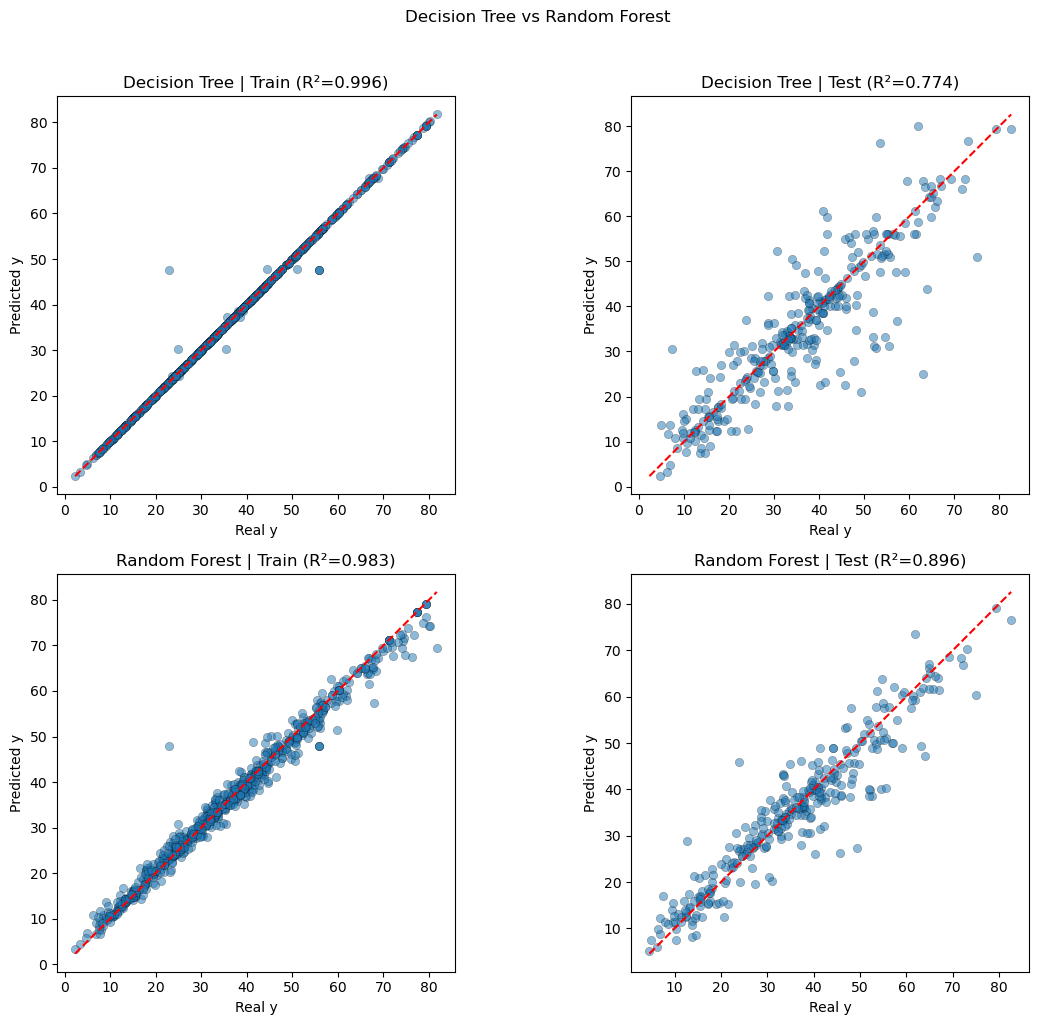

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

plot_info = [
    (0, 0, Y_train_reg, models["Decision Tree"]["train_pred"], "Decision Tree | Train"),
    (0, 1, Y_test_reg,  models["Decision Tree"]["test_pred"],  "Decision Tree | Test"),
    (1, 0, Y_train_reg, models["Random Forest"]["train_pred"], "Random Forest | Train"),
    (1, 1, Y_test_reg,  models["Random Forest"]["test_pred"],  "Random Forest | Test"),
]

for row, col, y_true, y_pred, title in plot_info:
    ax = axes[row, col]
    ax.scatter(y_true, y_pred, alpha=0.5, edgecolors="k", linewidths=0.3)
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax.plot(lims, lims, "r--", lw=1.5)
    ax.set_xlabel("Real y")
    ax.set_ylabel("Predicted y")
    ax.set_title(f"{title} (R²={r2_score(y_true, y_pred):.3f})")
    ax.set_aspect("equal", adjustable="box")

plt.suptitle("Decision Tree vs Random Forest", y=1.02)
plt.tight_layout()
plt.show()

Random Forest가 항상 Train·Test 모두에서 더 좋은 것은 아니지만,
Train은 낮고 Test는 더 높다면 → 앙상블이 과적합을 줄이고 일반화 성능을 올린 것으로 해석하면 됩니다.

**[과제 3]** 지수는 Random Forest의 성능을 더 높이기 위해 하이퍼파라미터 튜닝을 시도하려고 합니다. 하지만 n_estimators, max_depth, min_samples_split, max_features 등의 의미와 적절한 범위를 잘 모릅니다. AI와 상의하여 각 하이퍼파라미터의 역할을 이해하고 탐색 범위를 직접 설정해 보세요. 이후 GridSearchCV를 활용해 최적의 조합을 찾고, 왜 해당 조합이 선택되었는지 결과를 해석해 보세요.

In [27]:
# ============================================================
# Random Forest 하이퍼파라미터 튜닝 (GridSearchCV)
# ============================================================

# 1) 기본 모델 성능 (비교 기준)
RF_base = RandomForestRegressor(random_state=0)
RF_base.fit(X_train_reg, Y_train_reg)
base_pred = RF_base.predict(X_test_reg)

print("=== 기본 모델 (Test) ===")
get_regscore(Y_test_reg, base_pred)

# 2) 탐색할 파라미터 그리드
params_reg = {
    "n_estimators":      [100, 200, 300],
    "max_depth":         [5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "max_features":      [2, 3, 4, 1.0],   # 변수 8개 기준
}

# 3) GridSearchCV
grid_reg = GridSearchCV(
    estimator=RandomForestRegressor(random_state=0),
    param_grid=params_reg,
    cv=5,              # 5-fold 교차검증
    scoring="r2",      # 회귀: R² 최대화
    n_jobs=-1,         # CPU 병렬
    return_train_score=True,
    verbose=1          # 진행 상황 출력 (선택)
)

grid_reg.fit(X_train_reg, Y_train_reg)

# 4) CV 결과 요약
print("\n=== GridSearchCV 결과 ===")
print("최적 파라미터:", grid_reg.best_params_)
print("최적 CV R² (평균): %.4f" % grid_reg.best_score_)

# 5) 상위 5개 조합 확인
cv_results = pd.DataFrame(grid_reg.cv_results_)
top5 = cv_results.sort_values("rank_test_score").head(5)[
    ["params", "mean_test_score", "std_test_score", "mean_train_score"]
]
print("\n=== 상위 5개 조합 ===")
print(top5.to_string(index=False))

# 6) 최적 모델로 Test 평가
best_pred_reg = grid_reg.predict(X_test_reg)

print("\n=== 튜닝 후 모델 (Test) ===")
get_regscore(Y_test_reg, best_pred_reg)

# 7) 기본 vs 튜닝 비교
print("\n=== Test R² 비교 ===")
print(f"기본 모델 : {r2_score(Y_test_reg, base_pred):.4f}")
print(f"튜닝 모델 : {r2_score(Y_test_reg, best_pred_reg):.4f}")
print(f"개선폭    : {r2_score(Y_test_reg, best_pred_reg) - r2_score(Y_test_reg, base_pred):+.4f}")

=== 기본 모델 (Test) ===
MSE       : 26.678
RMSE      : 5.165
MAE       : 3.583
R-squared : 0.896
Fitting 5 folds for each of 144 candidates, totalling 720 fits

=== GridSearchCV 결과 ===
최적 파라미터: {'max_depth': 15, 'max_features': 4, 'min_samples_split': 2, 'n_estimators': 100}
최적 CV R² (평균): 0.9002

=== 상위 5개 조합 ===
                                                                           params  mean_test_score  std_test_score  mean_train_score
{'max_depth': 15, 'max_features': 4, 'min_samples_split': 2, 'n_estimators': 100}         0.900169        0.009589          0.982299
{'max_depth': 15, 'max_features': 4, 'min_samples_split': 2, 'n_estimators': 200}         0.898169        0.008476          0.982687
{'max_depth': 20, 'max_features': 4, 'min_samples_split': 2, 'n_estimators': 300}         0.898154        0.007774          0.982886
{'max_depth': 15, 'max_features': 4, 'min_samples_split': 2, 'n_estimators': 300}         0.898125        0.008379          0.982863
{'max_depth': 20, 'max

나무 깊이 15개로 제한, 변수 4개 선택을 통해 과적합을 개선

**[과제 4]**
지수는 Random Forest에서 나무의 개수(n_estimators)를 많이 늘릴수록 성능이 계속 좋아지는지 궁금해졌습니다. AI와 상의하여 다양한 n_estimators 값(예: 10, 50, 100, 200, 500 등)으로 모델을 학습시키고 성능 변화를 그래프로 시각화해 보세요. 성능 향상과 학습 시간의 변화를 함께 확인한 뒤, 실무에서는 어떤 값을 선택하는 것이 적절할지 의견을 정리해 보세요.